In [1]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [11]:
%%writefile MyDetectionMethods.py
"""
MyDetectionMethods.py  -  Lab 2 (Step 1)

Class built from the pre-processing steps of Lab 1, exercise 6
(Canny filter + binarization). Each method takes image data (BGR frame)
and returns contours.

Image path inside each method:
    BGR frame -> gray -> blur -> Canny | binarization -> remove blobs touching
    the image border (table edge) -> findContours -> area filter -> contours
"""
import cv2
import numpy as np


class MyDetectionMethods:
    def __init__(self, min_area=200):
        self.min_area = min_area      # ignore tiny contours (noise), in pixel^2
        self.last_processed = None    # last edge/binary image (for debugging)

    # ------------------------------------------------------------------ helpers
    def _gray_blur(self, image):
        """BGR -> gray -> light Gaussian blur (reduces camera noise)."""
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        return cv2.GaussianBlur(gray, (7, 7), 0)

    @staticmethod
    def estimate_background(image):
        """Brightness of the background (the paper) = most common gray value."""
        gray = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), (7, 7), 0)
        return int(np.argmax(np.bincount(gray.ravel(), minlength=256)))

    def _clean_and_contours(self, binary):
        """Remove blobs that touch the image border (table edge etc.) and tiny
        blobs, then return the outer contours of what is left."""
        n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
        h, w = binary.shape
        keep = np.zeros(n, np.uint8)
        for i in range(1, n):
            x, y, bw, bh, area = stats[i]
            touches = x <= 2 or y <= 2 or x + bw >= w - 2 or y + bh >= h - 2
            if area >= self.min_area and not touches:
                keep[i] = 255
        binary = keep[labels]
        self.last_processed = binary
        contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL,
                                       cv2.CHAIN_APPROX_SIMPLE)
        return contours

    # ---------------- Method A: Canny filter (as in Lab 1 ex. 6) ----------------
    def canny_filter(self, image, low=30, high=90):
        gray = self._gray_blur(image)
        edges = cv2.Canny(gray, low, high)
        # close small gaps so each object's edge becomes one closed loop
        edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE,
                                 np.ones((5, 5), np.uint8), iterations=2)
        return self._clean_and_contours(edges)

    # ------- Method B: binarization relative to the background (default) --------
    def binarization(self, image, diff_frac=0.4):
        """Object = pixel clearly different from the background brightness.
        Works for dark objects on a grey/white paper even in dim light."""
        gray = self._gray_blur(image)
        bg = self.estimate_background(image)
        thr = max(15, diff_frac * bg)
        binary = (np.abs(gray.astype(np.int16) - bg) > thr).astype(np.uint8) * 255
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE,
                                  np.ones((5, 5), np.uint8), iterations=2)
        return self._clean_and_contours(binary)

    # ---------------- Method C: Otsu binarization (Lab 1 ex. 6) -----------------
    def binarization_otsu(self, image):
        gray = self._gray_blur(image)
        _, binary = cv2.threshold(gray, 0, 255,
                                  cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        if np.mean(binary) > 127:                 # make sure objects are white
            binary = cv2.bitwise_not(binary)
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE,
                                  np.ones((5, 5), np.uint8), iterations=2)
        return self._clean_and_contours(binary)

Overwriting MyDetectionMethods.py


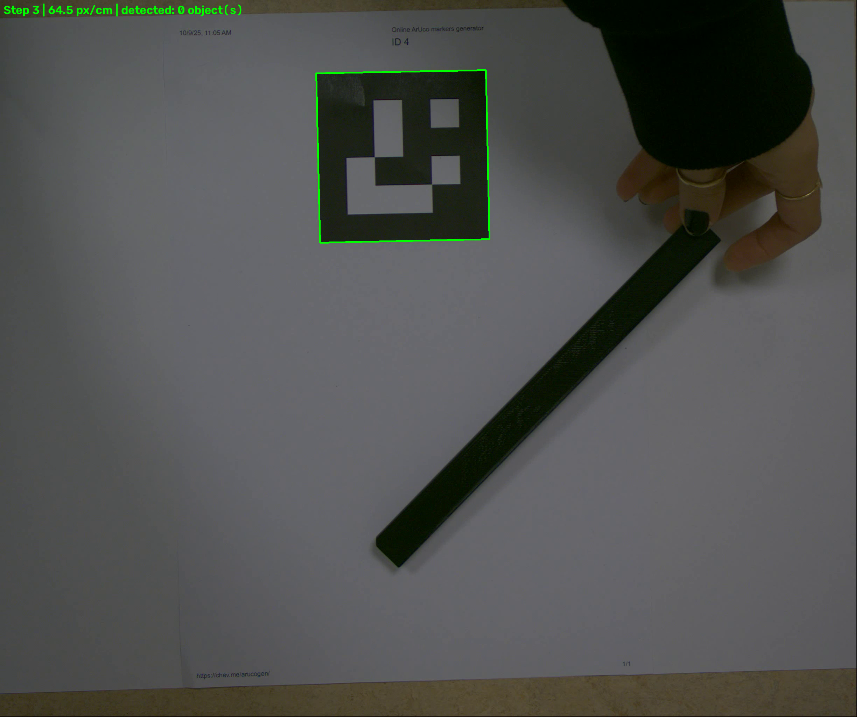

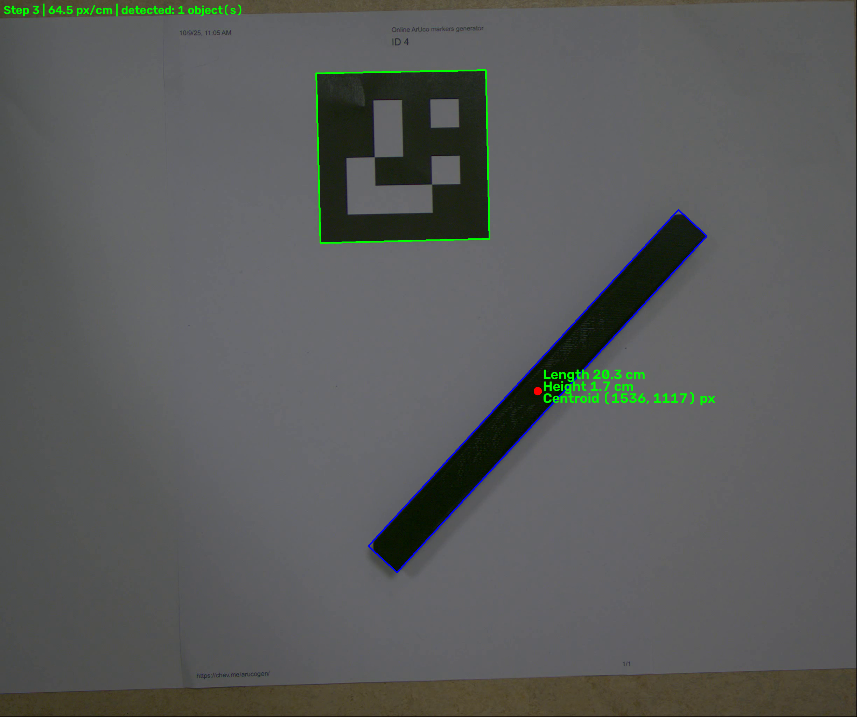

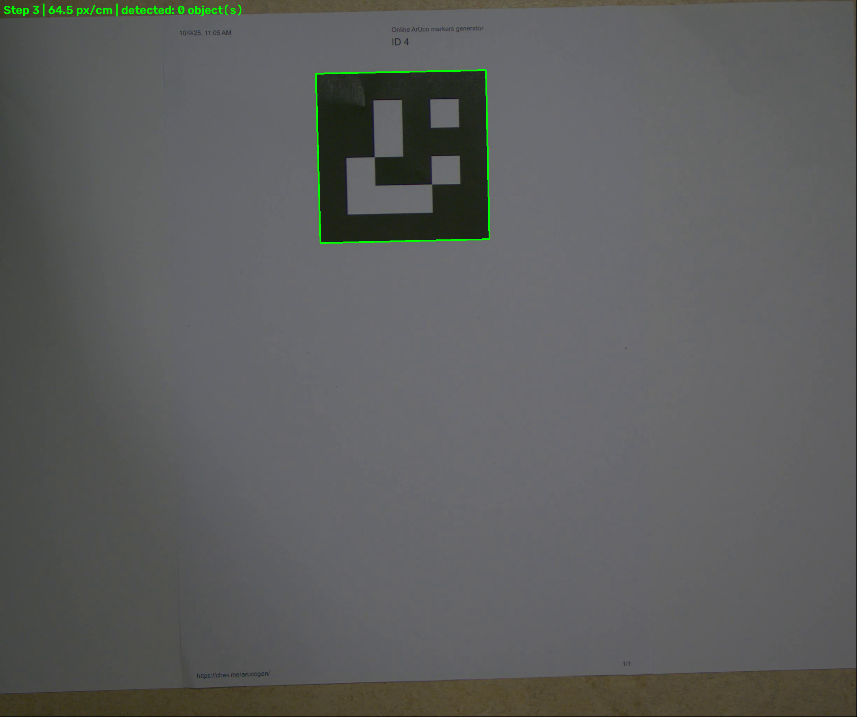

/content/drive/MyDrive/RCS600/single_objects.mp4 -> step3_single.mp4: 292 frames, max objects in one frame = 2


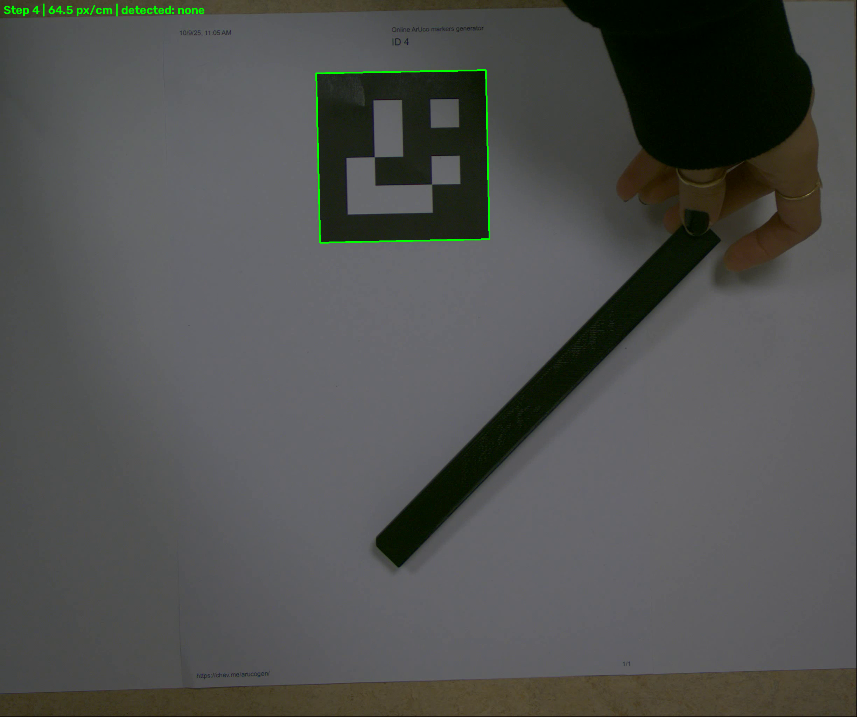

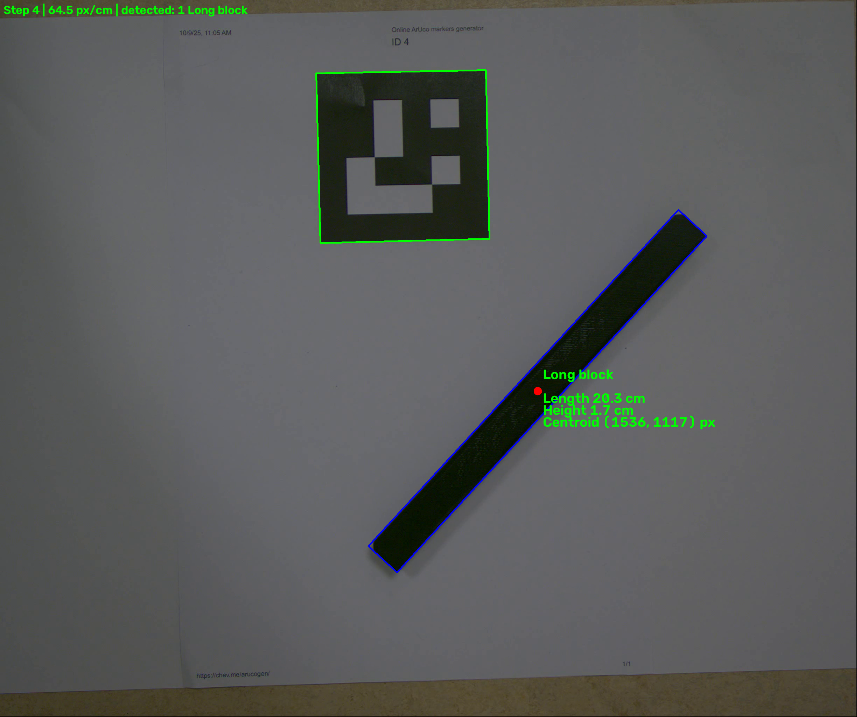

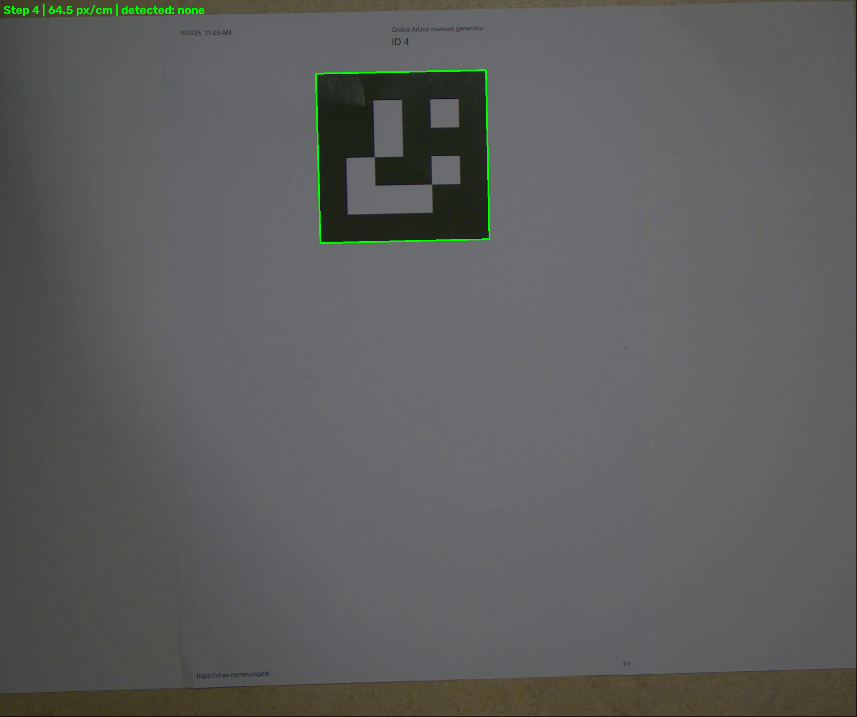

/content/drive/MyDrive/RCS600/single_objects.mp4 -> step4_single.mp4: 292 frames, max objects in one frame = 1


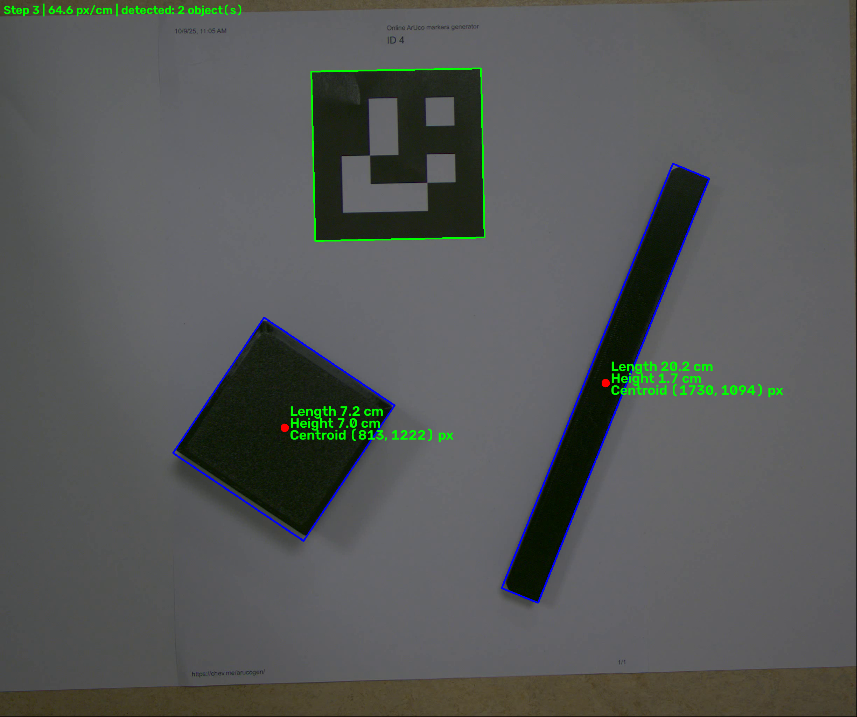

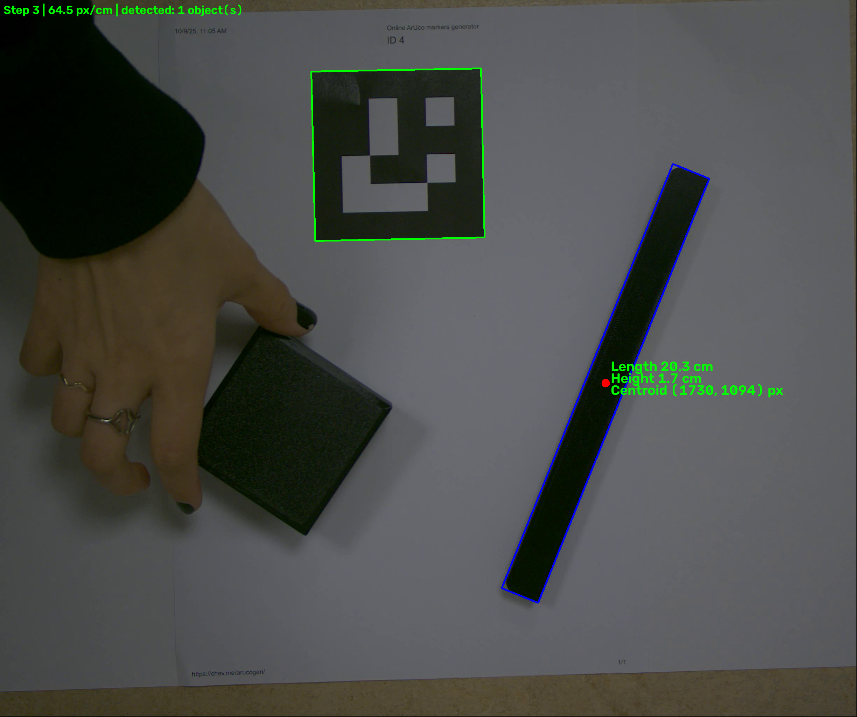

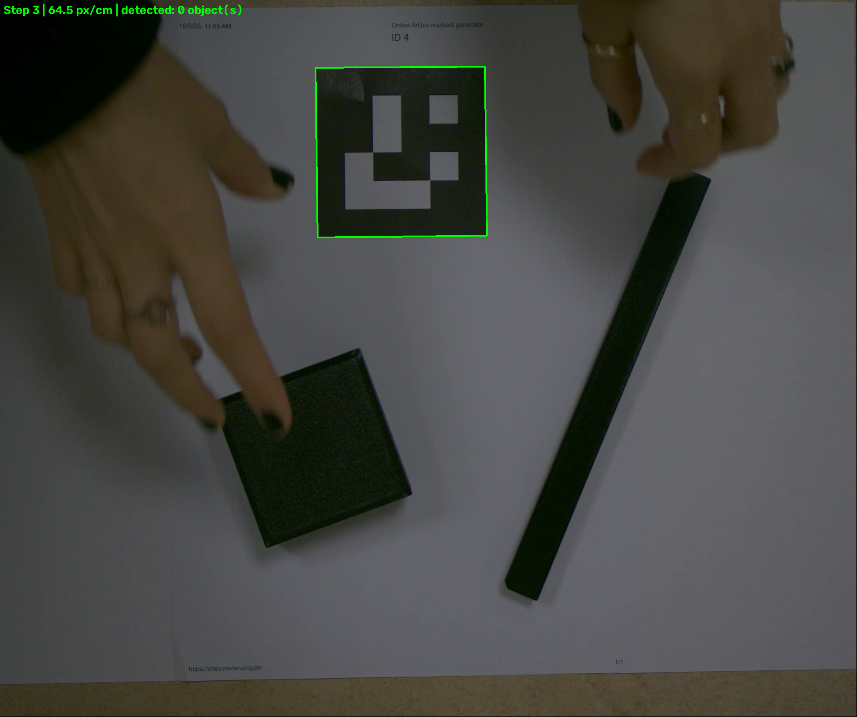

/content/drive/MyDrive/RCS600/multiple_objects.mp4 -> step3_multiple.mp4: 315 frames, max objects in one frame = 4


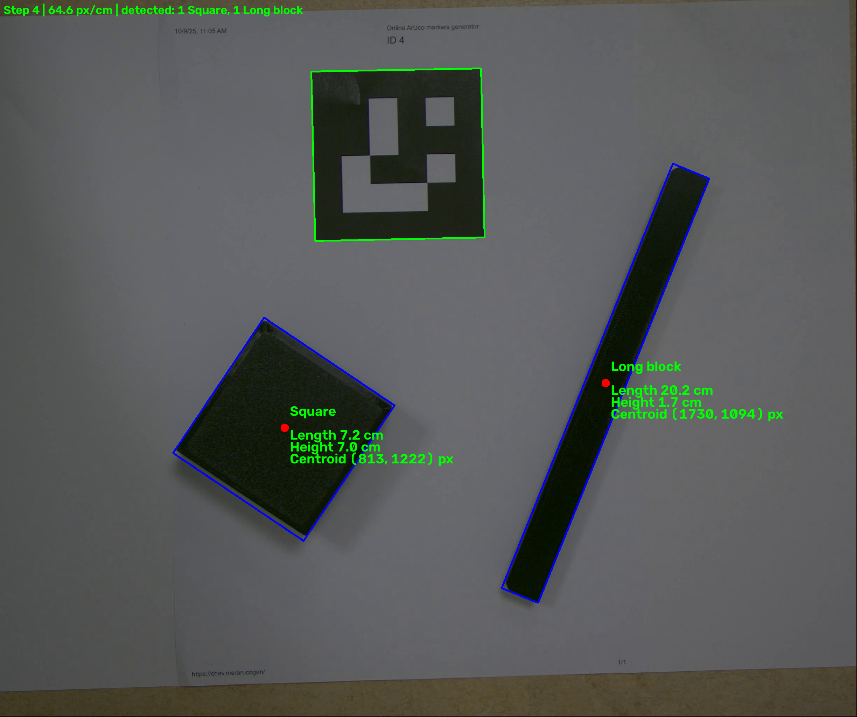

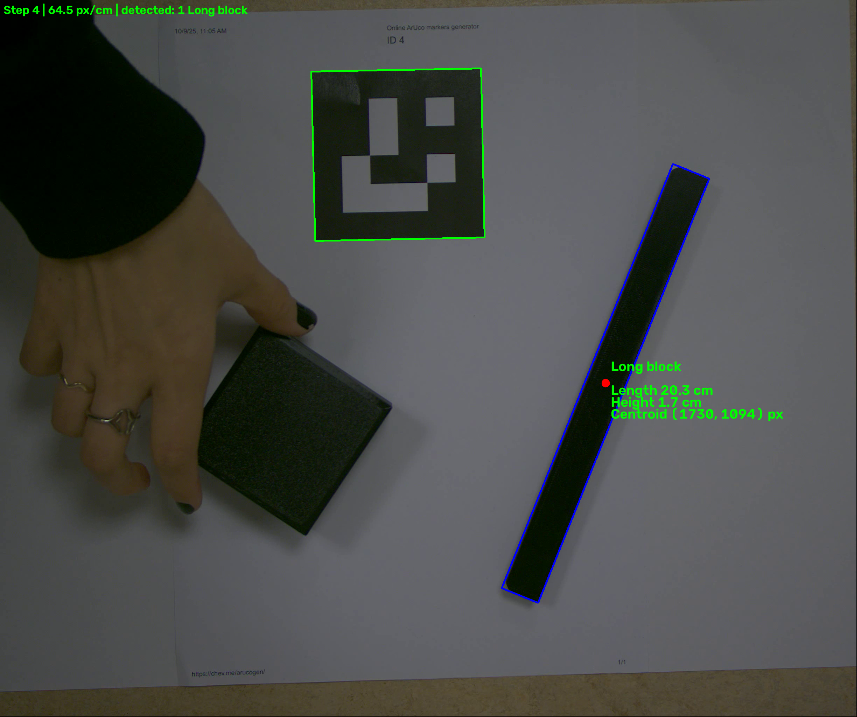

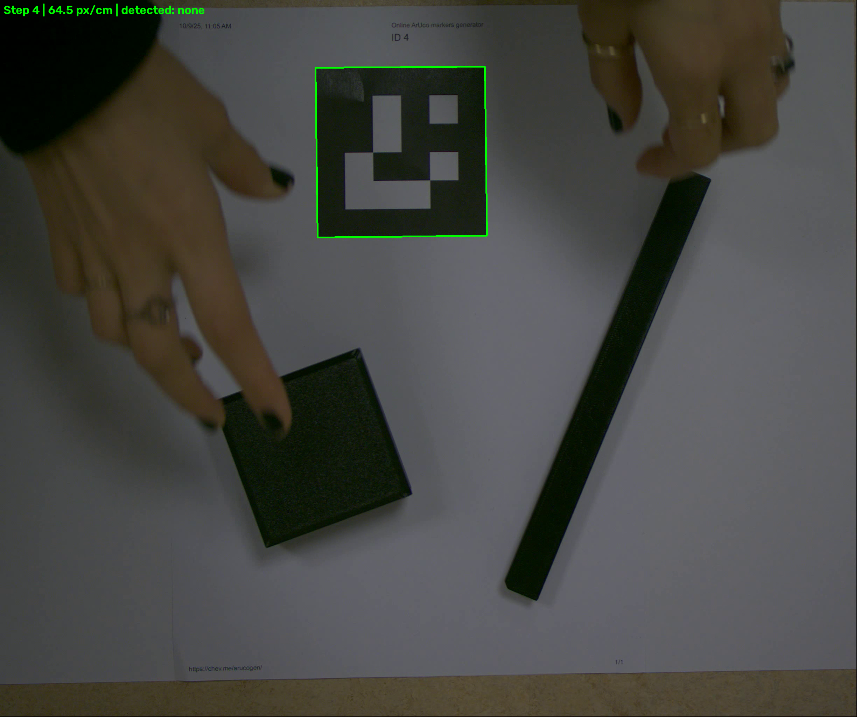

/content/drive/MyDrive/RCS600/multiple_objects.mp4 -> step4_multiple.mp4: 315 frames, max objects in one frame = 2


In [14]:
"""
main_colab.py  -  Lab 2 (Steps 2, 3, 4), Google Colab version

IDEA: the ArUco marker (4x4, 75 mm) is only a RULER. It gives the pixel-to-cm
ratio. The things we detect/measure are the objects lying next to it
(one object at a time, or two objects at the same time).

Image "travel" through the program (per frame):
    video frame -> gray -> detectMarkers -> marker corners (green box)
      -> pixel_per_cm = marker side in px / 7.5 cm
         (marker hidden? -> keep using the last good ratio, orange box)
      -> marker painted with the background colour (so it is NOT an object)
      -> MyDetectionMethods (binarization / Canny) -> contours of the objects
      -> filter (size in cm^2, not touching image border)
      -> minAreaRect (rotated box) -> px -> cm, centroid from image moments
      -> Step 3: show Length / Height / centroid of every object
         Step 4: name the object (Long block / Square / Phone), ignore the rest
      -> annotated frame -> output video
"""

import os
import cv2
import numpy as np
from MyDetectionMethods import MyDetectionMethods

try:                                           # Colab: show images in the notebook
    from google.colab.patches import cv2_imshow
except ImportError:                            # outside Colab: do nothing
    def cv2_imshow(img):
        pass

# ----------------------------------------------------------------- settings
MARKER_SIZE_CM = 7.5         # ArUco 4x4, 75 mm (black square side)
TOL_CM = 0.6                 # size tolerance in cm (lab text: +/- 5 mm; 6 mm leaves a little margin)

# Objects of the lab videos: (long side, short side) in cm
TARGETS = {
    "Long block": (20.0, 1.6),    # 16 x 200 mm
    "Square":     (7.2, 7.0),     # 70 x 72 mm
    "Phone":      (16.9, 8.2),    # 82 x 169 mm
}

MIN_AREA_CM2 = 1.0           # smaller blobs are noise
MAX_FRAME_FRACTION = 0.4     # a "contour" bigger than 40 % of the image = background
BORDER_PX = 5                # contours touching the image border are ignored


# ---------------------------------------------------------------- ArUco 4x4
def make_detector(dict_id):
    """Works with old (<4.7) and new (>=4.7) OpenCV aruco API."""
    if hasattr(cv2.aruco, "ArucoDetector"):                    # new API
        dictionary = cv2.aruco.getPredefinedDictionary(dict_id)
        detector = cv2.aruco.ArucoDetector(dictionary, cv2.aruco.DetectorParameters())
        return lambda gray: detector.detectMarkers(gray)[:2]
    dictionary = cv2.aruco.Dictionary_get(dict_id)             # old API (lab text)
    params = cv2.aruco.DetectorParameters_create()
    return lambda gray: cv2.aruco.detectMarkers(gray, dictionary, parameters=params)[:2]


detect_markers = make_detector(cv2.aruco.DICT_4X4_50)


def side_length_px(pts):
    """Average of the 4 marker sides, in pixels."""
    return np.mean([np.linalg.norm(pts[i] - pts[(i + 1) % 4]) for i in range(4)])


# ------------------------------------------------------------------ helpers
def is_valid_object(contour, px_per_cm, frame_shape):
    """Reject noise, the background/table and anything cut by the image border."""
    h, w = frame_shape[:2]
    if cv2.contourArea(contour) / px_per_cm ** 2 < MIN_AREA_CM2:
        return False
    x, y, bw, bh = cv2.boundingRect(contour)
    if x <= BORDER_PX or y <= BORDER_PX or x + bw >= w - BORDER_PX or y + bh >= h - BORDER_PX:
        return False
    if bw * bh > MAX_FRAME_FRACTION * w * h:
        return False
    return True


def measure(contour, px_per_cm):
    """Rotated bounding box -> (box points, center, long side cm, short side cm)."""
    (cx, cy), (w, h), angle = cv2.minAreaRect(contour)
    box = cv2.boxPoints(((cx, cy), (w, h), angle)).astype(int)
    return box, (int(cx), int(cy)), max(w, h) / px_per_cm, min(w, h) / px_per_cm


def centroid(contour):
    """Centroid from image moments (same idea as Lab 1 exercise 6)."""
    M = cv2.moments(contour)
    if M["m00"] == 0:
        return None
    return int(M["m10"] / M["m00"]), int(M["m01"] / M["m00"])


def classify(length_cm, height_cm):
    """Step 4: name of the target whose size matches within +/- TOL_CM, else None."""
    best = None
    for name, (L, S) in TARGETS.items():
        dl, ds = abs(length_cm - L), abs(height_cm - S)
        if dl <= TOL_CM and ds <= TOL_CM and (best is None or dl + ds < best[0]):
            best = (dl + ds, name)
    return best[1] if best else None


def put_text(img, text, org, color=(0, 255, 0), scale=0.7):
    k = max(img.shape[1] / 1280.0, 1.0)           # scale text with the image size
    cv2.putText(img, text, org, cv2.FONT_HERSHEY_SIMPLEX, scale * k, color, max(2, int(2 * k)))


# ---------------------------------------------------------------- processing
def process_video(video_path, out_path, step=3, method="binary", preview_frames=3):
    """
    step   : 3 = measure every object, 4 = recognise Long block / Square / Phone only
    method : "binary" (default) | "canny" | "otsu"
    Returns the largest number of objects seen in one frame.
    """
    tools = MyDetectionMethods(min_area=300)
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print("Could not open", video_path)
        return 0
    fps = cap.get(cv2.CAP_PROP_FPS) or 20
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

    ratio, last_pts = None, None     # last good pixel-per-cm and marker corners
    n, shown, max_objects = 0, 0, 0
    while True:
        ok, frame = cap.read()
        if not ok or frame is None:          # video ended: no frames left -> stop
            break
        n += 1
        display = frame.copy()
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # ---- Step 2: find the marker = our ruler ---------------------------------
        corners, ids = detect_markers(gray)
        marker_visible = False
        if ids is not None and len(corners) > 0:
            pts = corners[0].reshape(4, 2)
            now = side_length_px(pts) / MARKER_SIZE_CM
            # accept only plausible values (a half-hidden marker can give a wrong size)
            if ratio is None or abs(now - ratio) / ratio < 0.10:
                ratio = now if ratio is None else 0.9 * ratio + 0.1 * now   # smoothing
                last_pts = pts
                marker_visible = True

        if ratio is None:                    # marker never seen yet -> cannot measure
            put_text(display, "No ArUco marker yet", (10, 40), (0, 0, 255))
            writer.write(display)
            continue

        if marker_visible:
            cv2.polylines(display, [last_pts.astype(int)], True, (0, 255, 0), 4)   # green
        else:
            # marker hidden behind an object: camera is fixed, so keep the last ratio
            cv2.polylines(display, [last_pts.astype(int)], True, (0, 165, 255), 4)  # orange
            put_text(display, "Marker hidden - using last px/cm", (10, 80), (0, 165, 255))
        px_per_cm = ratio

        # ---- paint the marker with the background colour (not an object) ---------
        clean = frame.copy()
        bg = tools.estimate_background(frame)
        margin = max(3, int(0.06 * side_length_px(last_pts)))
        cv2.fillConvexPoly(clean, cv2.convexHull(last_pts.astype(np.int32)), (bg, bg, bg))
        cv2.polylines(clean, [last_pts.astype(int)], True, (bg, bg, bg), margin)

        # ---- Step 1 class: contours of everything that is not background ---------
        if method == "canny":
            contours = tools.canny_filter(clean)
        elif method == "otsu":
            contours = tools.binarization_otsu(clean)
        else:
            contours = tools.binarization(clean)
        contours = [c for c in contours if is_valid_object(c, px_per_cm, frame.shape)]

        # ---- Step 3 / Step 4: measure the objects -----------------------------------
        found = {}
        dy = int(18 * max(W / 1280.0, 1.0))
        for c in contours:
            box, box_ctr, length_cm, height_cm = measure(c, px_per_cm)
            ctr = centroid(c) or box_ctr
            if step == 3:
                label = "object"
                title = None
            else:
                label = classify(length_cm, height_cm)
                if label is None:
                    continue                              # all other objects ignored
                title = label
            cv2.drawContours(display, [box], 0, (255, 0, 0), 3)
            cv2.circle(display, ctr, max(6, W // 200), (0, 0, 255), -1)   # centroid (red)
            y = ctr[1] - dy
            if title:
                put_text(display, title, (ctr[0] + 15, y)); y += 2 * dy
            put_text(display, f"Length {length_cm:.1f} cm", (ctr[0] + 15, y))
            put_text(display, f"Height {height_cm:.1f} cm", (ctr[0] + 15, y + dy))
            put_text(display, f"Centroid ({ctr[0]}, {ctr[1]}) px", (ctr[0] + 15, y + 2 * dy))
            found[label] = found.get(label, 0) + 1

        count = sum(found.values())
        max_objects = max(max_objects, count)
        summary = (f"{count} object(s)" if step == 3 else
                   ", ".join(f"{v} {k}" for k, v in found.items())) or "none"
        put_text(display, f"Step {step} | {px_per_cm:.1f} px/cm | detected: {summary}",
                 (10, 40), scale=0.6)
        writer.write(display)

        if shown < preview_frames and n % 40 == 0:       # small preview in the notebook
            cv2_imshow(cv2.resize(display, None, fx=0.35, fy=0.35))
            shown += 1

    cap.release()
    writer.release()
    print(f"{video_path} -> {out_path}: {n} frames, max objects in one frame = {max_objects}")
    return max_objects


# --------------------------- run it
# Upload single_objects.mp4 and multiple_objects.mp4 from Canvas first.
if __name__ == "__main__" or "get_ipython" in globals():
    JOBS = [
        ("/content/drive/MyDrive/RCS600/single_objects.mp4",   "step3_single.mp4",   3),   # one object at a time: measure
        ("/content/drive/MyDrive/RCS600/single_objects.mp4",   "step4_single.mp4",   4),   # one object at a time: recognise
        ("/content/drive/MyDrive/RCS600/multiple_objects.mp4", "step3_multiple.mp4", 3),   # two objects at once: measure
        ("/content/drive/MyDrive/RCS600/multiple_objects.mp4", "step4_multiple.mp4", 4),   # two objects at once: recognise
    ]
    for src, dst, st in JOBS:
        if os.path.exists(src):
            process_video(src, dst, step=st, method="binary")
        else:
            print("Missing video:", src)